# YOLO11n Dropout Architecture Comparison

Compare the same pretrained YOLO11n detector with feature-map dropout rates of 0%, 20%, and 40%. Dropout is inserted immediately before the Detect head. This changes the detector architecture while keeping the YOLO11n backbone/neck and training setup consistent.

## Install

In [8]:
%pip install -q -U ultralytics pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 40.1 MB/s eta 0:00:00


## Settings

Set `DATA` to the dataset YAML available in this runtime. Keep the same seed, split, image size, batch, and epochs across runs for a fair comparison.

In [2]:
from pathlib import Path
import time
import pandas as pd
import torch
from IPython.display import display
from ultralytics import YOLO

DATA = "african-wildlife.yaml"
EPOCHS = 100
IMGSZ = 640
BATCH = 16
SEED = 42
DEVICE = 0 if torch.cuda.is_available() else "cpu"
PROJECT = "runs/yolo11n_dropout_comparison"

VARIANTS = {
    "YOLO11n": 0.0,
    "YOLO11n_Dropout20": 0.20,
    "YOLO11n_Dropout40": 0.40,
}
Path(PROJECT).mkdir(parents=True, exist_ok=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## Add architecture dropout before Detect

For detection, the training `dropout` option is not the mechanism for adding dropout to YOLO11n's detection head. This cell attaches `Dropout2d` to the three feature maps entering the Detect head. It is active during training and automatically inactive during validation/inference.

In [3]:
import torch.nn as nn

def add_detect_feature_dropout(yolo_model, p):
    """Insert channel-wise dropout on each feature map entering the Detect head."""
    detect = next((m for m in yolo_model.model.modules()
                   if m.__class__.__name__ == "Detect"), None)
    if detect is None:
        raise RuntimeError("Could not find a Detect head in this YOLO model.")

    dropout = nn.Dropout2d(p=p) if p > 0 else nn.Identity()

    def dropout_inputs(module, inputs):
        if not inputs:
            return inputs
        features = inputs[0]
        if isinstance(features, (list, tuple)):
            features = type(features)(dropout(x) for x in features)
            return (features, *inputs[1:])
        return (dropout(features), *inputs[1:])

    detect.register_forward_pre_hook(dropout_inputs)
    return yolo_model

## Train the three variants

Each run starts from the same `yolo11n.pt` pretrained checkpoint and identical settings. Results are written to separate run folders.

In [4]:
training_times = {}
best_weights = {}

for name, dropout_rate in VARIANTS.items():
    model = YOLO("yolo11n.pt")
    add_detect_feature_dropout(model, dropout_rate)

    start = time.time()
    model.train(
        data=DATA,
        epochs=EPOCHS,
        imgsz=IMGSZ,
        batch=BATCH,
        device=DEVICE,
        seed=SEED,
        patience=20,
        project=PROJECT,
        name=name.lower(),
        exist_ok=True,
        pretrained=True,
        plots=True,
    )
    training_times[name] = time.time() - start
    best_weights[name] = str(Path(model.trainer.save_dir) / "weights" / "best.pt")

print("Completed runs:", list(best_weights))

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=african-wildlife.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n, nbs=64, nms=None, opset=None, optimize=False, optimizer=au

## Evaluate on the held-out test split

Use the same test split for all variants. The saved YOLO checkpoint retains the original layer weights; the same dropout architecture is reattached for evaluation (dropout is inactive in eval mode).

In [5]:
comparison = []

for name, dropout_rate in VARIANTS.items():
    model = YOLO(best_weights[name])
    add_detect_feature_dropout(model, dropout_rate)
    metrics = model.val(
        data=DATA,
        split="test",
        imgsz=IMGSZ,
        batch=BATCH,
        device=DEVICE,
        plots=True,
    )
    comparison.append({
        "Model": name,
        "Dropout rate": dropout_rate,
        "Precision": metrics.box.mp,
        "Recall": metrics.box.mr,
        "mAP50": metrics.box.map50,
        "mAP50-95": metrics.box.map,
        "mAP75": metrics.box.map75,
        "Training time (min)": training_times[name] / 60,
        "Best weights": best_weights[name],
    })

comparison_df = pd.DataFrame(comparison).sort_values(
    "mAP50-95", ascending=False
).reset_index(drop=True)
display(comparison_df.style.format({
    "Dropout rate": "{:.0%}",
    "Precision": "{:.4f}", "Recall": "{:.4f}",
    "mAP50": "{:.4f}", "mAP50-95": "{:.4f}",
    "mAP75": "{:.4f}", "Training time (min)": "{:.2f}",
}))

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2260.3±1127.4 MB/s, size: 141.3 KB)
val: Scanning /content/datasets/african-wildlife/labels/test... 227 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 227/227 2.0Kit/s 0.1s
val: New cache created: /content/datasets/african-wildlife/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.3it/s 3.5s
                   all        227        375      0.962      0.931      0.975      0.838
               buffalo         49         66      0.963      0.894      0.966      0.861
              elephant         58         99      0.949      0.938      0.976      0.816
                 rhino         55         75      0.986       0.96      0.982      0.898
                 zebra         66        135 

,Model,Dropout rate,Precision,Recall,mAP50,mAP50-95,mAP75,Training time (min),Best weights
0,YOLO11n,0%,0.9616,0.9312,0.9746,0.8378,0.9128,31.01,/content/runs/detect/runs/yolo11n_dropout_comparison/yolo11n/weights/best.pt
1,YOLO11n_Dropout20,20%,0.9675,0.9172,0.9661,0.8211,0.9065,30.65,/content/runs/detect/runs/yolo11n_dropout_comparison/yolo11n_dropout20/weights/best.pt
2,YOLO11n_Dropout40,40%,0.9612,0.8766,0.9500,0.7836,0.8849,30.97,/content/runs/detect/runs/yolo11n_dropout_comparison/yolo11n_dropout40/weights/best.pt


In [ ]:
comparison_df.to_csv(Path(PROJECT) / "model_comparison.csv", index=False)
comparison_df.to_json(Path(PROJECT) / "model_comparison.json", orient="records", indent=2)

best_row = comparison_df.iloc[0]
print(f"Top test mAP50-95: {best_row['Model']} ({best_row['mAP50-95']:.4f})")

<Axes: title={'center': 'YOLO11n Detection Feature-Dropout Comparison'}, xlabel='Model'>

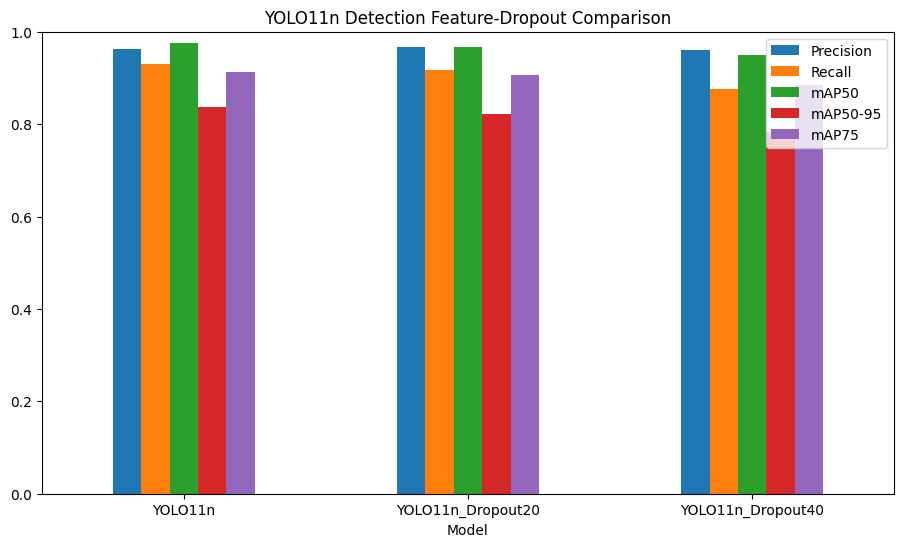

In [7]:
comparison_df.set_index("Model")[["Precision", "Recall", "mAP50", "mAP50-95", "mAP75"]].plot(
    kind="bar", figsize=(11, 6), ylim=(0, 1), rot=0,
    title="YOLO11n Detection Feature-Dropout Comparison"
)

## Interpretation

* Primary Metric: Compare test $mAP50-95$ first, then check recall (missed animals) and precision (false alarms).
* Statistical Rigor: A single random seed only gives a rough comparison; use multiple shared seeds and compare averages and variation for strong evidence.
* Dropout Settings: The 20% and 40% settings refer to channel-wise dropout on the detection head's three feature maps, not the built-in classification dropout argument.